In [1]:
import pandas as pd

df = pd.read_csv("../results/strong_pool/job-30371/scaling.csv")

print("Total measurements:", len(df))
print("Worker counts:", sorted(df["workers"].unique()))
print("Repetitions per worker:")
print(df.groupby("workers").size())

Total measurements: 30
Worker counts: [np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32)]
Repetitions per worker:
workers
1     5
2     5
4     5
8     5
16    5
32    5
dtype: int64


In [2]:
summary = df.groupby("workers")["time"].agg(
    median="median",
    minimum="min",
    maximum="max"
).sort_index()

baseline_time = summary.loc[1, "median"]

summary["speedup"] = baseline_time / summary["median"]
summary["efficiency_pct"] = 100 * summary["speedup"] / summary.index

summary["serial_fraction"] = (
    (1 / summary["speedup"]) - (1 / summary.index)
) / (1 - 1 / summary.index)

summary.loc[1, "serial_fraction"] = float("nan")

print(summary.round(3).to_string())

          median  minimum  maximum  speedup  efficiency_pct  serial_fraction
workers                                                                     
1        122.611  122.489  123.648    1.000         100.000              NaN
2         61.862   61.698   62.197    1.982          99.100            0.009
4         31.184   31.029   31.511    3.932          98.296            0.006
8         15.877   15.714   16.033    7.722          96.531            0.005
16         8.782    8.556    8.875   13.961          87.257            0.010
32         5.019    4.849    5.336   24.429          76.341            0.010


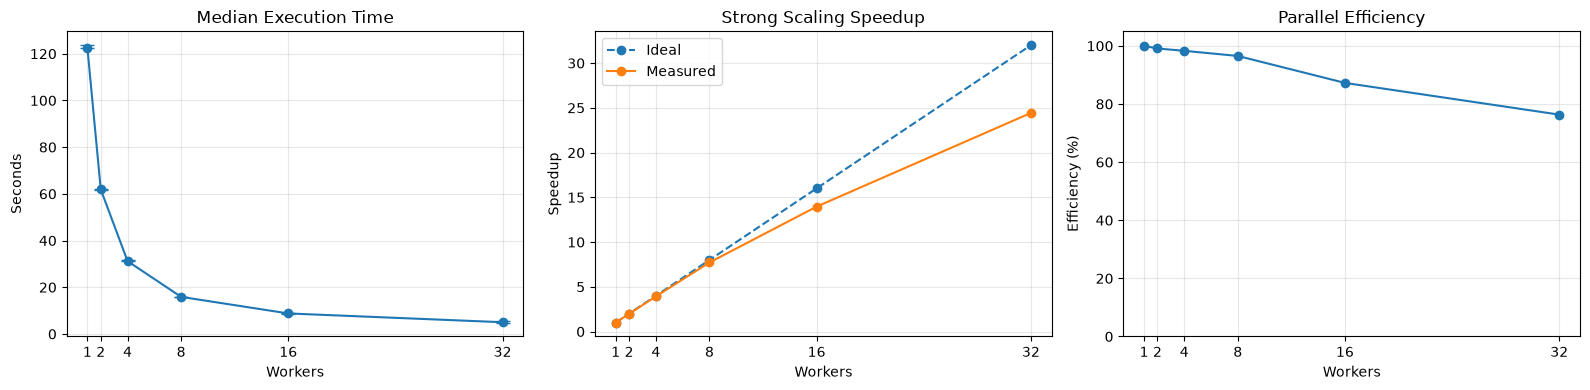

In [3]:
import matplotlib.pyplot as plt

workers = summary.index.to_numpy()
medians = summary["median"].to_numpy()
mins = summary["minimum"].to_numpy()
maxs = summary["maximum"].to_numpy()
speedups = summary["speedup"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].errorbar(
    workers, medians,
    yerr=[medians - mins, maxs - medians],
    fmt="o-", capsize=5
)
axes[0].set_title("Median Execution Time")
axes[0].set_xlabel("Workers")
axes[0].set_ylabel("Seconds")

axes[1].plot(workers, workers, "o--", label="Ideal")
axes[1].plot(workers, speedups, "o-", label="Measured")
axes[1].set_title("Strong Scaling Speedup")
axes[1].set_xlabel("Workers")
axes[1].set_ylabel("Speedup")
axes[1].legend()

axes[2].plot(workers, summary["efficiency_pct"], "o-")
axes[2].set_title("Parallel Efficiency")
axes[2].set_xlabel("Workers")
axes[2].set_ylabel("Efficiency (%)")
axes[2].set_ylim(0, 105)

for ax in axes:
    ax.set_xticks(workers)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../results/plots/strong_scaling.png", dpi=200)
plt.show()

# Cluster Scaling and Profiling Analysis

**Data:** Slurm job 30371, 2,000,000 simulated seasons, 1, 2, 4, 8, 16 and 32 workers, 5 repetitions each.

**Result:** the median time fell from 122.61 s with 1 worker to 5.02 s with 32 workers: a **24.4× speedup** at **76.3% efficiency**.

**Why efficiency drops:**
- Up to 8 workers efficiency stays above 96%.
- It already drops at 16 workers (87.3%), where every worker still has its own core: workers share the node's memory bandwidth and caches, and pool startup grows with more workers (0.004 s → 0.04 s).
- It drops further at 32 workers (76.3%): the job had 62 CPUs = 31 physical cores (64-CPU user limit minus our 2-CPU JupyterLab session), so two workers had to share one core.

**Serial fraction, estimated three ways:**

| Source | Serial fraction |
|---|---|
| Profile (job 30261) | ≈ 0.4–0.5% |
| Characterization (job 29781) | ≈ 0.8% |
| Amdahl's law from scaling (job 30371) | ≈ 0.5–1.0% |

The estimates are close. Amdahl's value is a little higher because it also absorbs the parallel overhead the law itself leaves out: starting workers, collecting results and sharing cores.

**Profile:** `simulate_batch` takes 19.92 s of the 20.53 s total, so almost all the work sits in independent batches that can run in parallel.